<a href="https://colab.research.google.com/github/MaryGit-24/egocentric-dishwashing-segmentation/blob/main/egocentric_dishwashing_train_v1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Egocentric Dishwashing Segmentation: Training v1

Trains a YOLO26 instance segmentation model on 246 chest mounted video frames (hand, dish, basin, sponge, soap container), labeled with Roboflow auto labeling and reviewed by hand.

In [1]:
!pip install -q ultralytics

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Unzip the dataset

Change `ZIP` to the exact name of your uploaded file.

In [4]:
ZIP = '/content/drive/MyDrive/Colab Notebooks/Colab Data/Egocentric Dishwashing Lagos.v1i.yolo26.zip'   # file path
!unzip -q -o "$ZIP" -d /content/data
!ls /content/data

data.yaml  README.dataset.txt  README.roboflow.txt  test  train  valid


## 3. Fix the dataset paths

Roboflow writes relative paths; this points them at the unzipped folders.

In [5]:
import yaml
CFG = '/content/data/data.yaml'
d = yaml.safe_load(open(CFG))
d['path'] = '/content/data'
d['train'] = 'train/images'
d['val'] = 'valid/images'
d['test'] = 'test/images'
yaml.safe_dump(d, open(CFG, 'w'))
print(d['names'])

['Basin', 'Dish', 'Hand', 'Soap Container', 'Sponge']


## 4. Train

About 20 to 40 minutes on a T4. `patience=20` stops early if the model stops improving. Ultralytics adds light augmentation (flips, colour shifts) during training by default; that is normal.

If `yolo26n-seg.pt` gives a not found error, use `yolo11n-seg.pt` instead and note it in the README.

In [6]:
from ultralytics import YOLO
model = YOLO('yolo26n-seg.pt')
model.train(data=CFG, epochs=100, imgsz=640, batch=16, patience=20,
            project='/content/runs', name='dish_v1', exist_ok=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7dd9c0451b70>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,  

## 5. Score on the test frames

These 24 frames were never seen in training. Write down the mask mAP50 and the per class table.

In [7]:
best = YOLO('/content/runs/dish_v1/weights/best.pt')
m = best.val(data=CFG, split='test')
print('Mask mAP50:', round(m.seg.map50, 3))
print('Mask mAP50-95:', round(m.seg.map, 3))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-seg summary (fused): 137 layers, 2,704,755 parameters, 0 gradients, 9.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1091.1±277.1 MB/s, size: 25.0 KB)
val: Scanning /content/data/test/labels... 24 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 24/24 1.3Kit/s 0.0s
val: New cache created: /content/data/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.0it/s 1.0s
                   all         24         87      0.898      0.843      0.901      0.743      0.888      0.829      0.874      0.736
                 Basin          5          5      0.907          1      0.995      0.915      0.911          1      0.995      0.995
                  Dish         21         33       0.96      0.725      0.869       0.64      0.879      0.659      0.727       0.55
   

## 6. See the predictions

Saves the test frames with outlines drawn on them.


image 1/24 /content/data/test/images/IMG_2137_mov-0004_jpg.rf.3ebfff9414d911770a96e888c915e1c1.jpg: 640x640 (no detections), 12.4ms
image 2/24 /content/data/test/images/IMG_2137_mov-0014_jpg.rf.3c10911a84de2b393a6dea4e18f363d9.jpg: 640x640 2 Dishs, 1 Hand, 2 Sponges, 13.9ms
image 3/24 /content/data/test/images/IMG_2137_mov-0016_jpg.rf.2f5d75eeb3c918314a6ee85e076c9bc9.jpg: 640x640 2 Dishs, 2 Hands, 2 Sponges, 15.8ms
image 4/24 /content/data/test/images/IMG_2137_mov-0022_jpg.rf.623866a874e46fdda7d393acb058bca0.jpg: 640x640 1 Basin, 2 Dishs, 1 Hand, 2 Sponges, 14.6ms
image 5/24 /content/data/test/images/IMG_2137_mov-0031_jpg.rf.986380244d906b89cfdaf2b5f778eb4b.jpg: 640x640 4 Dishs, 2 Hands, 1 Soap Container, 1 Sponge, 13.1ms
image 6/24 /content/data/test/images/IMG_2137_mov-0044_jpg.rf.e1f3e4838ee6ecd8b02bfa40d023dbc9.jpg: 640x640 1 Basin, 2 Dishs, 2 Hands, 1 Sponge, 12.7ms
image 7/24 /content/data/test/images/IMG_2137_mov-0045_jpg.rf.85b5a4c05f8a6b9a8b13a4e4af0a7ce5.jpg: 640x640 2 Dishs

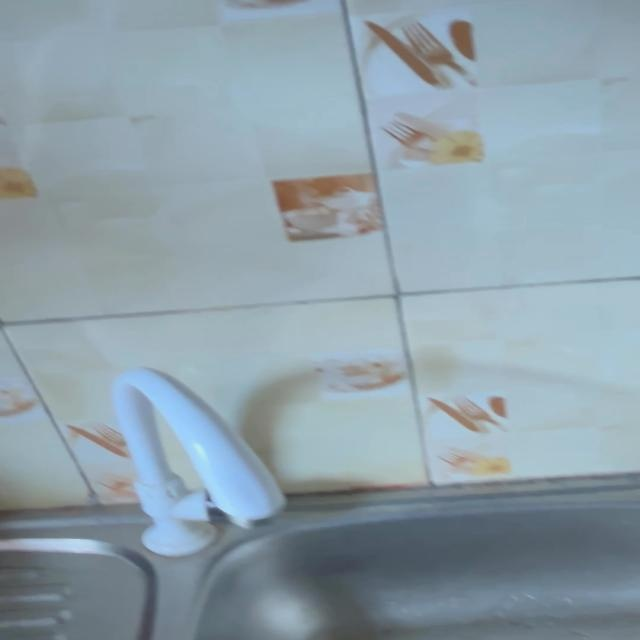

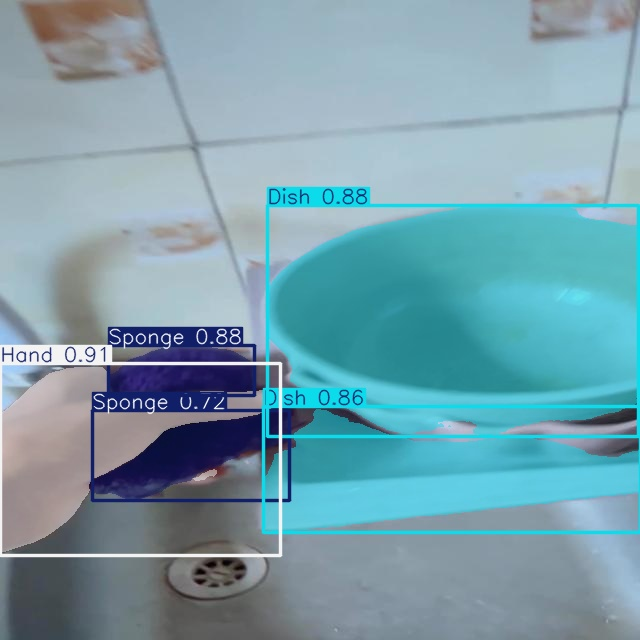

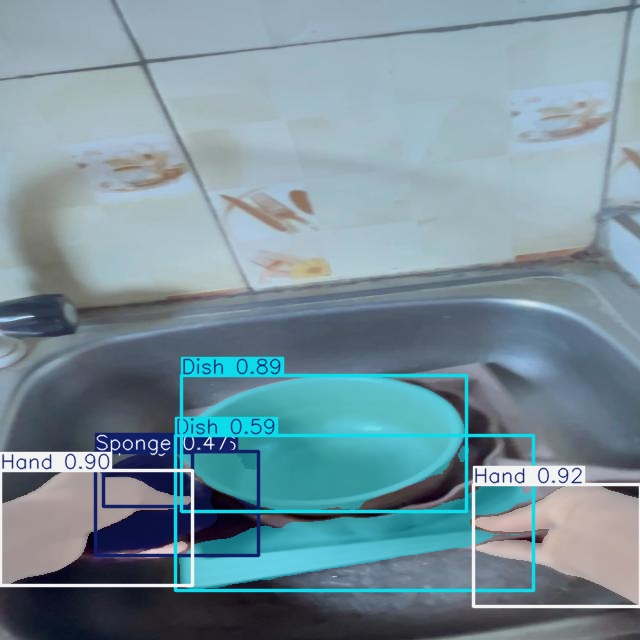

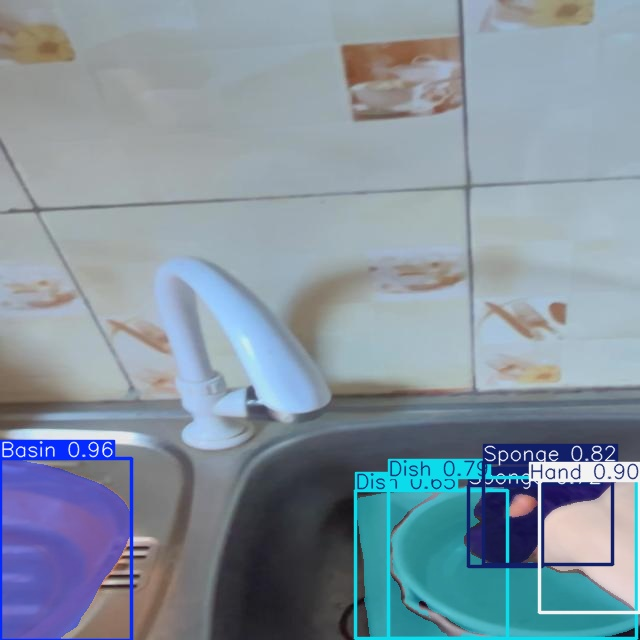

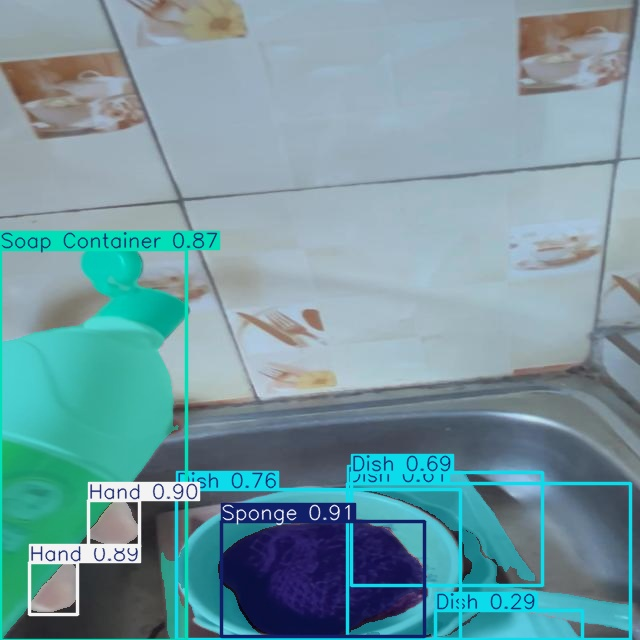

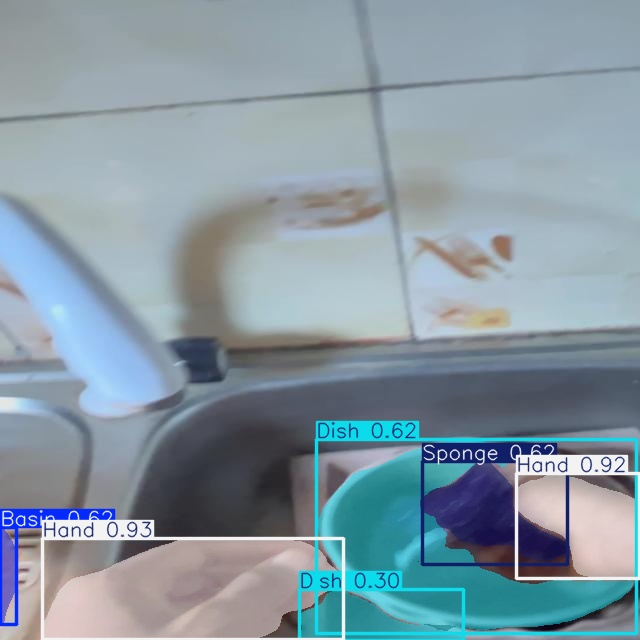

In [8]:
best.predict('/content/data/test/images', save=True, conf=0.25,
             project='/content/runs', name='test_preds', exist_ok=True)
from IPython.display import Image, display
import glob
for f in sorted(glob.glob('/content/runs/test_preds/*.jpg'))[:6]:
    display(Image(filename=f, width=300))

## 7. Download everything

Weights, charts and prediction images in one zip, for GitHub.

In [9]:
!cd /content && zip -q -r results.zip runs
from google.colab import files
files.download('/content/results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>